Prelim data

In [1]:
# my jupyter notebook on my computer does not work so I used google drive, change these imports based off of your own computer
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [6]:
# Paths to Excel files
inventory_path = '/content/drive/MyDrive/ProjectCS506/BottleFillersInventory-ongoing.xlsx'
high_volume_event_spaces_path = '/content/drive/MyDrive/ProjectCS506/HighVolumeEventSpaces.xlsx'
building_and_kitchen_list_path = '/content/drive/MyDrive/ProjectCS506/BuildingandKitchenList.xlsx'

# Convert Bottle Fillers Inventory to CSV
df_inventory = pd.read_excel(inventory_path)
df_inventory.to_csv('/content/drive/MyDrive/ProjectCS506/inventory_existing_filling_stations.csv', index=False)
print('Converted Bottle Fillers Inventory to inventory_existing_filling_stations.csv')

# Convert High Volume Event Spaces to CSV
df_high_volume = pd.read_excel(high_volume_event_spaces_path)
df_high_volume.to_csv('/content/drive/MyDrive/ProjectCS506/high_volume_event_spaces.csv', index=False)
print('Converted High Volume Event Spaces to high_volume_event_spaces.csv')

# Convert Building and Kitchen List to separate CSV files
xls = pd.ExcelFile(building_and_kitchen_list_path)

# Save "Building List" sheet
df_building_list = pd.read_excel(xls, sheet_name='Building List')
df_building_list.to_csv('/content/drive/MyDrive/ProjectCS506/building_list.csv', index=False)
print('Converted Building List to building_list.csv')

# Save "Rooms with Kitchens" sheet
df_rooms_with_kitchens = pd.read_excel(xls, sheet_name='Rooms with Kitchens')
df_rooms_with_kitchens.to_csv('/content/drive/MyDrive/ProjectCS506/rooms_with_kitchens.csv', index=False)
print('Converted Rooms with Kitchens to rooms_with_kitchens.csv')


/usr/local/lib/python3.10/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Data Validation extension is not supported and will be removed
  warn(msg)


Converted Bottle Fillers Inventory to inventory_existing_filling_stations.csv
Converted High Volume Event Spaces to high_volume_event_spaces.csv
Converted Building List to building_list.csv
Converted Rooms with Kitchens to rooms_with_kitchens.csv


In [7]:
# Load the datasets
inventory_existing_stations = pd.read_csv('/content/drive/MyDrive/ProjectCS506/inventory_existing_filling_stations.csv')
building_list = pd.read_csv('/content/drive/MyDrive/ProjectCS506/building_list.csv')
rooms_with_kitchens = pd.read_csv('/content/drive/MyDrive/ProjectCS506/rooms_with_kitchens.csv')
high_volume_event_spaces = pd.read_csv('/content/drive/MyDrive/ProjectCS506/high_volume_event_spaces.csv')
density_data = pd.read_csv('/content/drive/MyDrive/ProjectCS506/updated_densitymap_hourly_cleaned.csv')



In [29]:
# Quick data inspection
print(inventory_existing_stations.head())
print(building_list.head())
print(rooms_with_kitchens.head())
print(high_volume_event_spaces.head())
print(density_data.head())

# print("Inventory Existing Stations Columns:")
# print(inventory_existing_stations.columns.tolist())
# print("\nBuilding List Columns:")
# print(building_list.columns.tolist())
# print("\nRooms with Kitchens Columns:")
# print(rooms_with_kitchens.columns.tolist())
# print("\nHigh Volume Event Spaces Columns:")
# print(high_volume_event_spaces.columns.tolist())
# print("\nDensity Data Columns:")
# print(density_data.columns.tolist())


# Strip whitespace from column names for all dataframes
inventory_existing_stations.columns = inventory_existing_stations.columns.str.strip()
building_list.columns = building_list.columns.str.strip()
rooms_with_kitchens.columns = rooms_with_kitchens.columns.str.strip()
high_volume_event_spaces.columns = high_volume_event_spaces.columns.str.strip()
density_data.columns = density_data.columns.str.strip()


  Floor                                        Description Accessibility  \
0     1  Hallway across from vending machines, across f...        Public   
1     1                             Kitchenette, Room 116A    Restricted   
2     2                              Kitchenette, Room 222    Restricted   
3     0                               Hallway by bathrooms           NaN   
4     1                         Hallway by electrical room           NaN   

  Handicap Accessible Space@Bu room  Quantity       Date Installed  \
0                 Yes           191       1.0                  NaN   
1                 Yes          116A       1.0                  NaN   
2                 Yes           222       1.0                  NaN   
3                 NaN           B81       1.0  2023-12-01 00:00:00   
4                 NaN           181       1.0                  NaN   

                                    Type  \
0  Combo Bottle Filler/Drinking Fountain   
1              Office-Style Water 

# **Combining the Address A and Address B columns from the inventory of existing stations data to make a full address, and also converting all floors into integers**

In [9]:
# Standardize Addresses
inventory_existing_stations['Full Address'] = inventory_existing_stations['Address A'] + ' ' + inventory_existing_stations['Address B']
inventory_existing_stations.drop(['Address A', 'Address B'], axis=1, inplace=True)

In [11]:
# the Pool in fitrec is considered a floor, just making a comment so that we know this

# Standardize Floor Information
def standardize_floor_info(floor):
    # Handle NaN values
    if floor is None or pd.isna(floor):
        return np.nan
    # Convert all inputs to lower case strings to standardize processing
    floor_str = str(floor).strip().lower()

    # Map specific string values to their numeric equivalents
    floor_map = {
        'basement': 0,
        'first': 1,
        'second': 2,
        'third': 3,
        'fourth': 4,
        'fifth': 5,
        'sixth': 6,
        'seventh': 7,
        'eighth': 8,
        'ninth': 9,
        'tenth': 10,
        'lobby': 1,
        'ground': 1,
        'l1': 0,
        'pool': -2
    }

    # Check if the floor_str is directly in the map
    if floor_str in floor_map:
        return floor_map[floor_str]

    # Attempt to convert numbered floors like '23rd' to '23'
    elif floor_str.rstrip('thndstrd').isdigit():
        return int(floor_str.rstrip('thndstrd'))
    # Return the original string if no conditions are met
    # This line can be adjusted if you wish to handle unrecognized floors differently
    return floor_str


# Apply the function
inventory_existing_stations['Floor'] = inventory_existing_stations['Floor'].apply(standardize_floor_info)




# **Cleaning the rooms_with_kitchens data to make floor B into floor 0, and to only keep a column when it has one of these things:**

*   a value of 'Residential' in the Building Type (BLDGTYPE) columns
*   an existing value (meaning it is not empty) in the Classroom Use Extensions (EXTCLASS)  columns
*   an existing value (meaning it is not empty) in the General Use Facilities Room Use Extensions (EXTGENERAL) column

**I believe this is what it means to be publically accessible but may have to be changed**

In [23]:
print(rooms_with_kitchens.columns)



Index(['Site Code (SITECODE)', 'Building Code (BLDGCODE)',
       'Building Description (BLDGDESC)', 'Building Type (BLDGTYPE)',
       'Floor (FLOORCODE)', 'Room # (RMID)', 'Cost Object Code (GROUP_)',
       'Cost Object Name (GROUPDESC)', 'FICM Code (SPACETYPE)',
       'FICM Name (SPACETYPDS)', 'Area (AREA)', 'Room Name (RMNAME)',
       'Room Note (RM_NOTE)', 'Classroom Use Extensions (EXTCLASS)',
       'Office Facilities Room Use Extensions (EXTOFFICE)',
       'General Use Facilities Room Use Extensions (EXTGENERAL)',
       'Residential Facilities Room Use Extensions (EXTRESID)'],
      dtype='object')


In [27]:
# some columns that are originally not B or a number are being changed to NaN values because of this, might need to change this
rooms_with_kitchens['Floor (FLOORCODE)'] = rooms_with_kitchens['Floor (FLOORCODE)'].apply(lambda x: '0' if x == 'B' else x)

# Step 2: Filter rows based on conditions
# A value of 'Residential' in BLDGTYPE or non-empty in EXTCLASS or EXTGENERAL
filtered_rooms = rooms_with_kitchens[
    (rooms_with_kitchens['Building Type (BLDGTYPE)'] == 'Residential') |
    (rooms_with_kitchens['Classroom Use Extensions (EXTCLASS)'].notnull()) |
    (rooms_with_kitchens['General Use Facilities Room Use Extensions (EXTGENERAL)'].notnull())
]

filtered_rooms

,Site Code (SITECODE),Building Code (BLDGCODE),Building Description (BLDGDESC),Building Type (BLDGTYPE),Floor (FLOORCODE),Room # (RMID),Cost Object Code (GROUP_),Cost Object Name (GROUPDESC),FICM Code (SPACETYPE),FICM Name (SPACETYPDS),Area (AREA),Room Name (RMNAME),Room Note (RM_NOTE),Classroom Use Extensions (EXTCLASS),Office Facilities Room Use Extensions (EXTOFFICE),General Use Facilities Room Use Extensions (EXTGENERAL),Residential Facilities Room Use Extensions (EXTRESID)
229,CRC,501,915 COMMONWEALTH AVENUE ...,Student Support ...,1.0,187,1229260000,SAR BU REHAB. SERVICES EP ...,315,OFFSRV ...,80.951339,\t\tKitchen ...,NaN,NaN,Kitchen/Kitchenette,,
230,CRC,503,925 COMMONWEALTH AVENUE ...,Athletic ...,NaN,C210,1870800000,ARENA ADM ...,685,MEETSV ...,705.995112,Burke Club Room Kitchen ...,NaN,NaN,,,
231,CRC,503,925 COMMONWEALTH AVENUE ...,Athletic ...,NaN,G122,1870800000,ARENA ADM ...,315,OFFSRV ...,230.328101,...,NaN,NaN,Kitchen/Kitchenette,,
232,CRC,503,925 COMMONWEALTH AVENUE ...,Athletic ...,NaN,G133,1890200000,External Event Administration ...,315,OFFSRV ...,165.158562,...,NaN,NaN,Kitchen/Kitchenette,,
235,CRC,503,925 COMMONWEALTH AVENUE ...,Athletic ...,NaN,L169,1870800000,ARENA ADM ...,635,FOODSV ...,1642.155866,Commissary Kitchen ...,Main Kitchen,NaN,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1196,CRC,955,98 MOUNTFORT STREET ...,Residential ...,4.0,402C,1970010000,RHO OFFICE OF HOUSING ...,950,APART ...,43.031982,...,NaN,,,,Kitchen
1197,CRC,956,100 MOUNTFORT STREET ...,Residential ...,1.0,101C,1970010000,RHO OFFICE OF HOUSING ...,950,APART ...,163.038196,...,NaN,,,,Kitchen
1198,CRC,956,100 MOUNTFORT STREET ...,Residential ...,2.0,201D,1970010000,RHO OFFICE OF HOUSING ...,950,APART ...,187.037448,...,NaN,,,,Kitchen
1199,CRC,956,100 MOUNTFORT STREET ...,Residential ...,3.0,301D,1970010000,RHO OFFICE OF HOUSING ...,950,APART ...,187.037448,...,NaN,,,,Kitchen


# **Attempting get measurements from the density data**

In [30]:
# Optionally pre-filter rows with zero capacity if they're not relevant
density_data_filtered = density_data[density_data['capacity'] != 0]

# Group the data by 'building_floor' and 'building_desc'
grouped_data = density_data_filtered.groupby(['building_floor', 'building_desc'])

# Calculate summary statistics for each group
density_summary = grouped_data.agg(
    average_density=('density_cnt', 'mean'),
    max_density=('density_cnt', 'max'),
    total_density=('density_cnt', 'sum'),
    average_capacity=('capacity', 'mean'),
    # Calculate dc_ratio_avg efficiently without replacing zero capacities in advance
    dc_ratio_avg=('dc_ratio', 'mean')
)

# Reset index if you want 'building_floor' and 'building_desc' back as columns
density_summary.reset_index(inplace=True)

print(density_summary.head())

  building_floor       building_desc  average_density  max_density  \
0              1    1 BUSWELL STREET         2.028651           10   
1              1   1 UNIVERSITY ROAD        51.585595          351   
2              1     10 BUICK STREET        34.685260          194   
3              1     10 LENOX STREET         6.610296           36   
4              1  100 ASHFORD STREET        13.874281          331   

   total_density  average_capacity  dc_ratio_avg  
0           2903          7.000000      0.289623  
1        1206845        314.362513      0.167659  
2         868068        150.595557      0.229484  
3          96431         49.318275      0.142120  
4         231645        619.056720      0.022649  


# **Creating graph showing the top 10% calculated density floors in buildings**

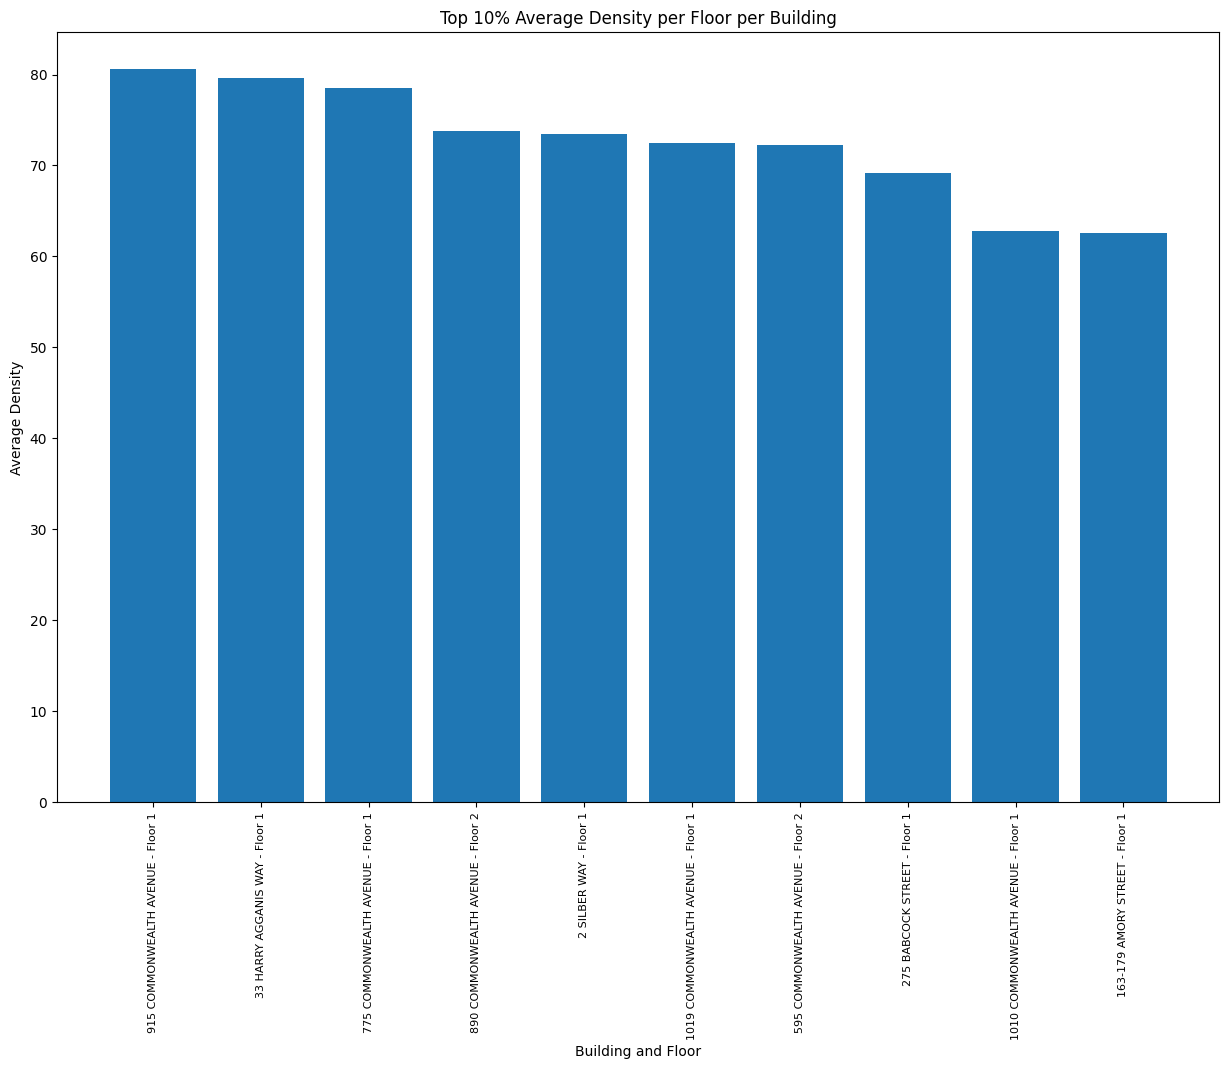

In [48]:
# Calculate the 80th percentile of 'average_density' to get the top 10%
threshold = np.percentile(density_summary['average_density'], 90)

# Filter the DataFrame to keep only the top 20%
top_10_percent_density = density_summary[density_summary['average_density'] >= threshold]

# Sort this filtered data for better visualization, if desired
top_10_percent_density_sorted = top_10_percent_density.sort_values(by='average_density', ascending=False)

# Create a new column for plotting that combines building and floor
top_10_percent_density_sorted['building_floor_desc'] = top_10_percent_density_sorted['building_desc'] + ' - Floor ' + top_10_percent_density_sorted['building_floor'].astype(str)

# Plotting the top 10%
fig, ax = plt.subplots(figsize=(15, 10))  # Adjust the size as needed

# Create a bar chart for the top 10%
ax.bar(top_10_percent_density_sorted['building_floor_desc'].head(10), top_10_percent_density_sorted['average_density'].head(10))

# Improve the chart
plt.xticks(rotation=90)  # Rotate labels to avoid overlap
ax.tick_params(axis='x', labelsize=8)
plt.xlabel('Building and Floor')
plt.ylabel('Average Density')
plt.title('Top 10% Average Density per Floor per Building')


# Show plot
plt.show()